# AUC im Mittelpunkt: beste historische Metriken gegen β und Rate

Nur die **240 vollständig ausgewerteten 90-Epochen-Läufe**, auf denen die Dateien in `results_26_09` und die Präsentation beruhen. **Keine neuen 750-Epochen-Läufe.**

1. Welche AUC-Unterschiede hängen mit β/d, Latentdimension und Seed zusammen?
2. Liefert eine einzelne Metrik zusätzliche Information **innerhalb gleicher β/d- und Dimensions-Einstellungen**?
3. Bleibt diese Assoziation bestehen, wenn zusätzlich die Rate berücksichtigt wird?

Das ist eine explorative Reanalyse derselben Daten, keine unabhängige Bestätigung und kein kausaler Nachweis. Das Notebook startet kein Training und verändert keine Quelldaten.

Die Hauptansicht zeigt Kandidaten aus den bisherigen Pearson-/Spearman-Ergebnissen und deren **zusätzlichen AUC-Zusammenhang nach Kontrolle der Rate**. Die vollständige 56-Metrik-Auswertung bleibt als CSV erhalten.


In [2]:
from pathlib import Path
import hashlib
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == 'beta_vae_experiments':
    ROOT = ROOT.parent
EXPERIMENTS = ROOT / 'beta_vae_experiments'
SWEEP = EXPERIMENTS / 'new_results_2026-09-29/biology_breakpoints_2026_09_29'
HISTORICAL = EXPERIMENTS / 'results_26_09'
OUTPUT = EXPERIMENTS / 'analysis_results/anova_26_09'
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True})


## Daten und Aufgaben

**Cancer:** gespeicherte native Validation-AUC auf einem z-Draw. **Sex:** `sex_mixed_z1` aus der historischen Nachauswertung, nur gemischte Krebsarten; dort wurden Validation und Test gepoolt. Die Aufgaben haben damit **unterschiedliche Evaluationsprotokolle**. Sex ist hier retrospektive Exploration, keine Testsatz-validierte Auswahl.

Die 56 Metriken werden aus der gespeicherten historischen Auswahl übernommen, nicht anhand der neuen ANOVA gewählt. Log-Rate kommt als explizite Baseline hinzu. Keine automatische Umkehr von Metrikrichtungen.


In [3]:
source_path = SWEEP / 'experiment_metrics.csv'
sex_path = HISTORICAL / '30_09_G16_geschlecht_gemischt.csv'
selection_path = HISTORICAL / '30_09_A_downstream_korrelation.csv'
data = pd.read_csv(source_path)
sex = pd.read_csv(sex_path)[['run_name', 'sex_mixed_z1']]
assert data.run_name.is_unique and sex.run_name.is_unique
assert len(data) == 240 and data.epochs.eq(90).all()
assert data.anneal_function.eq('no-annealing').all()
data = data.merge(sex, on='run_name', how='left', validate='one_to_one').copy()
data['beta_over_d'] = data.beta / data.latent_dim
# Float division can otherwise split one experimental beta into two categories.
data['beta_level'] = data.beta_over_d.map(lambda value: f'{value:.8g}')
data['settings_cell'] = data.beta_level + '_d' + data.latent_dim.astype(str)
data['trajectory'] = data.latent_dim.astype(str) + '_seed' + data.seed.astype(str)
data['log_rate'] = np.log(data.posterior_conditional_kl_total_mean.clip(lower=1e-12))
TASKS = {'cancer': 'downstream_CANCER_TYPE_ACRONYM_z_valid_roc_auc_ovo',
         'sex_mixed': 'sex_mixed_z1'}
selection = pd.read_csv(selection_path)
METRICS = [name for name in selection.Metrik if name in data] + ['log_rate']
FAMILIES = selection.set_index('Metrik').Family.to_dict() | {'log_rate': 'Rate baseline'}
assert len(METRICS) == len(set(METRICS))
MIN_COVERAGE = 0.80
EXCLUDE_FULL_COLLAPSE = True
ALPHA = 0.05
summary = data.groupby(['latent_dim', 'seed']).agg(models=('run_name', 'size'),
    cancer_scores=(TASKS['cancer'], 'count'), sex_scores=(TASKS['sex_mixed'], 'count'))
display(summary)
print(f'{len(data)} runs; {len(METRICS)-1} historical metrics + log-rate; {data.settings_cell.nunique()} settings cells.')

TOP_CORRELATIONS = 8
N_RESAMPLES = 1000
RESAMPLING_SEED = 31
SHOW_FULL_SCREENING = False
correlation_path = EXPERIMENTS / 'analysis_results/metric_selection/auc_correlations_summary.csv'
correlations = pd.read_csv(correlation_path).replace({'metric': {'logR': 'log_rate'}})
focus_rows = []
for task, historical_task in [('cancer', 'cancer'), ('sex_mixed', 'sex')]:
    candidates = correlations[correlations.task.eq(historical_task)
        & correlations['mode'].eq('values') & correlations.metric.isin(METRICS)].copy()
    for score in ['pearson', 'spearman']:
        top = candidates.loc[candidates[score].abs().nlargest(TOP_CORRELATIONS).index]
        focus_rows.extend(top.assign(task=task, selection_score=score).to_dict('records'))
focus = pd.DataFrame(focus_rows).groupby(['task', 'metric'], as_index=False).agg(
    pearson=('pearson', 'first'), spearman=('spearman', 'first'),
    selection_scores=('selection_score', lambda values: ','.join(sorted(set(values)))))
focus.to_csv(OUTPUT / 'historical_correlation_shortlist.csv', index=False)


models  cancer_scores  sex_scores
latent_dim seed                                   
2          13        10             10           9
           17        10             10           9
           23        10             10           9
           31        10             10           9
4          13        10             10           9
           17        10             10           9
           23        10             10           9
           31        10             10           9
6          13        10             10           9
           17        10             10           9
           23        10             10           9
           31        10             10           9
8          13        10             10           9
           17        10             10           9
           23        10             10           9
           31        10             10           9
12         13        10             10           9
           17        10             10           9
           23        10             10           9
           31        10             10           9
16         13        10             10           9
           17        10             10           9
           23        10             10           9
           31        10             10           9

240 runs; 56 historical metrics + log-rate; 60 settings cells.


## 1. ANOVA der Trainingseinstellungen

Additives Modell: `AUC ~ C(beta_level) + C(latent_dim) + C(seed)`, Typ-II-ANOVA. β/d ist **kategorial**, daher keine Annahme einer linearen β-Wirkung. Hier bleiben alle vorhandenen AUCs einschließlich β=0 und Collapse enthalten.

Die Tabelle beschreibt Mittelwertunterschiede. Ihre klassischen p-Werte setzen unabhängige Fehler voraus; die späteren metrischen Tests ergänzen eine Cluster-Korrektur für wiederholte β-Zustände derselben Seed-/Dimensions-Trajektorie.


In [4]:
settings_tables = []
for task, target in TASKS.items():
    sample = data.replace([np.inf, -np.inf], np.nan).dropna(subset=[target]).copy()
    sample['auc'] = sample[target]
    model = smf.ols('auc ~ C(beta_level) + C(latent_dim) + C(seed)', data=sample).fit()
    table = anova_lm(model, typ=2).reset_index(names='term')
    residual_ss = float(table.loc[table.term.eq('Residual'), 'sum_sq'].iloc[0])
    table['partial_eta_squared'] = table.sum_sq / (table.sum_sq + residual_ss)
    table.loc[table.term.eq('Residual'), 'partial_eta_squared'] = np.nan
    table = table.assign(task=task, n=len(sample))
    settings_tables.append(table)
    print(task)
    display(table)
settings_anova = pd.concat(settings_tables, ignore_index=True)
settings_anova.to_csv(OUTPUT / 'settings_anova.csv', index=False)


cancer


,term,sum_sq,df,F,PR(>F),partial_eta_squared,task,n
0,C(beta_level),5.623074,9.0,625.123557,2.352791e-152,0.962039,cancer,240
1,C(latent_dim),0.112166,5.0,22.445385,3.378767e-18,0.335781,cancer,240
2,C(seed),0.000800,3.0,0.266958,8.491732e-01,0.003595,cancer,240
3,Residual,0.221880,222.0,NaN,NaN,NaN,cancer,240


sex_mixed


,term,sum_sq,df,F,PR(>F),partial_eta_squared,task,n
0,C(beta_level),2.915624,8.0,115.102252,2.161714e-70,0.822293,sex_mixed,216
1,C(latent_dim),0.367628,5.0,23.221004,2.406906e-18,0.368465,sex_mixed,216
2,C(seed),0.010828,3.0,1.139959,3.340577e-01,0.016895,sex_mixed,216
3,Residual,0.630102,199.0,NaN,NaN,NaN,sex_mixed,216


## 2. Zusätzliche Metrik-Assoziation bei gleichen Einstellungen

**Basismodell:** `AUC ~ C(settings_cell) + C(seed)`. Jede Kombination aus β/d und d erhält einen eigenen Mittelwert; damit ist auch deren Interaktion kontrolliert. **Erweiterung:** eine standardisierte Metrik. Beide Modelle verwenden exakt dieselben Zeilen.

Berichtet werden zusätzlicher R²-Gewinn, partielles R², klassischer verschachtelter F-Test und ein **nach (d, Seed) geclusterter Koeffiziententest** mit Small-Sample-Korrektur und t-Verteilung. Nur 24 Trajektorien und vier Seeds je Zelle: diese Korrektur ist eine Sensitivitätsanalyse, keine Garantie korrekter Inferenz.

Primär werden vollständig kollabierte Modelle ausgeschlossen, damit gemeinsamer Kollaps die Metrik-Rangfolge nicht allein bestimmt. Die Entscheidung steht oben als Schalter. Metriken mit <80 % Coverage oder ohne verbleibende Variation nach Kontrolle werden explizit protokolliert.


In [5]:
def test_metric(task, target, metric, adjust_for_rate):
    eligible = data.copy()
    if EXCLUDE_FULL_COLLAPSE:
        eligible = eligible[eligible.posterior_collapsed_dimensions_fraction_eps_0p01_delta_0p01.lt(1)]
    eligible = eligible.replace([np.inf, -np.inf], np.nan).dropna(subset=[target])
    required = [metric] + (['log_rate'] if adjust_for_rate else [])
    sample = eligible.dropna(subset=required).copy()
    coverage = len(sample) / len(eligible) if len(eligible) else 0
    record = dict(task=task, metric=metric, family=FAMILIES[metric],
                  adjustment='settings_and_rate' if adjust_for_rate else 'settings',
                  n=len(sample), eligible_n=len(eligible), coverage=coverage)
    if coverage < MIN_COVERAGE or len(sample) < 10 or sample[metric].std() <= 1e-12:
        return record | dict(status='insufficient_data_or_variation')
    sample['auc'] = sample[target]
    sample['metric_z'] = (sample[metric] - sample[metric].mean()) / sample[metric].std()
    formula = 'auc ~ C(settings_cell) + C(seed)' + (' + log_rate' if adjust_for_rate else '')
    base = smf.ols(formula, data=sample).fit()
    added = smf.ols(formula + ' + metric_z', data=sample).fit()
    if added.model.rank != base.model.rank + 1 or added.df_resid < 2:
        return record | dict(status='not_identifiable_after_adjustment')
    # Metric must retain meaningful variation after removing the same covariates.
    residual_metric = sm.OLS(sample.metric_z, base.model.exog).fit().resid
    if np.std(residual_metric) < 1e-8:
        return record | dict(status='no_within_settings_variation')
    comparison = anova_lm(base, added).iloc[-1]
    robust = added.get_robustcov_results(cov_type='cluster', groups=sample.trajectory,
                                       use_correction=True, df_correction=True, use_t=True)
    index = added.model.exog_names.index('metric_z')
    partial_r2 = (base.ssr - added.ssr) / base.ssr if base.ssr > 1e-15 else np.nan
    return record | dict(status='ok', n_clusters=sample.trajectory.nunique(),
        coefficient=added.params.metric_z, coefficient_cluster_se=robust.bse[index],
        p_cluster=robust.pvalues[index], F=comparison['F'], p_F=comparison['Pr(>F)'],
        base_r2=base.rsquared, delta_r2=added.rsquared-base.rsquared,
        partial_r2=partial_r2, df_residual=added.df_resid)

records = []
for task, target in TASKS.items():
    for adjust_for_rate in (False, True):
        for metric in METRICS:
            if adjust_for_rate and metric == 'log_rate':
                continue
            records.append(test_metric(task, target, metric, adjust_for_rate))
results = pd.DataFrame(records)
# Each task and adjustment is a declared, separate exploratory testing family.
for _, group in results[results.status.eq('ok')].groupby(['task', 'adjustment']):
    for p_column, q_column in [('p_cluster', 'q_cluster'), ('p_F', 'q_F')]:
        indices = group.index[np.isfinite(group[p_column])]
        results.loc[indices, q_column] = multipletests(results.loc[indices, p_column], method='fdr_bh')[1]
results = results.sort_values(['task', 'adjustment', 'q_cluster', 'partial_r2'],
                              ascending=[True, True, True, False], na_position='last')
results.to_csv(OUTPUT / 'metric_anova.csv', index=False)
display(results.groupby(['task', 'adjustment', 'status']).size().rename('metrics').to_frame())


metrics
task      adjustment        status         
cancer    settings          ok           57
          settings_and_rate ok           56
sex_mixed settings          ok           57
          settings_and_rate ok           56

## Hauptauswertung: Welche bisher gut korrelierte Metrik weiß mehr als β und Rate?

Je Aufgabe: Vereinigung der **Top 8 nach |Pearson| und Top 8 nach |Spearman|** der gespeicherten historischen Auswertung. Auswahlregel und Originalkorrelationen sind sichtbar; die Richtungen bleiben erhalten. Nicht auf die neuen ANCOVA-p-Werte zugeschnitten. Die Auswahl und Prüfung auf denselben historischen Daten bleibt trotzdem explorativ.

Die folgenden Tabellen berichten **AUC als Zielgröße**, Originalkorrelationen, zusätzliches partielles R² und Koeffizienten nach Kontrolle von β/d×Dimension, Seed und log-Rate. Log-Rate steht daneben als Baseline gegen β/Dimension/Seed; sie kann nicht zusätzlich gegen sich selbst getestet werden.


cancer — AUC beyond beta, dimension, seed and rate


,metric,pearson,spearman,coefficient,partial_r2,delta_r2,q_cluster,n
11,geometry_mu_steadiness_zadu_k20,0.982308,0.857143,0.055402,0.407695,0.014698,6.075089e-10,210
13,geometry_mu_trustworthiness_zadu_k20,0.988134,0.976190,0.064662,0.388883,0.014020,5.917396e-05,210
5,geometry_mu_lcmc_zadu_k20,0.984278,0.976190,0.061421,0.377781,0.013620,2.850769e-05,210
15,graph_directed_edge_jaccard_lcmc_related_k20,0.978814,0.976190,0.060907,0.368411,0.013282,7.152846e-05,210
7,geometry_mu_mrre_false_zadu_k20,0.990318,0.976190,0.044756,0.296598,0.010693,5.290807e-03,210
19,graph_partition_nmi_k20,0.980063,0.869048,0.041341,0.294695,0.010624,4.755711e-04,210
9,geometry_mu_scale_normalized_stress_zadu,-0.981008,-0.815476,-0.057987,0.256147,0.009235,1.034944e-03,210
3,geometry_mu_continuity_zadu_k20,0.974437,0.964286,0.049269,0.133829,0.004825,1.563156e-01,210
17,graph_latent_clustering_k20,-0.979170,-0.964286,-0.025756,0.054166,0.001953,1.640719e-01,210
22,topology_h0_persistence_entropy_mu,0.989940,0.964286,0.011325,0.014351,0.000517,5.396397e-01,210


Rate baseline after beta, dimension and seed:


,partial_r2,coefficient,q_cluster,n
56,0.034378,0.023101,0.324295,210


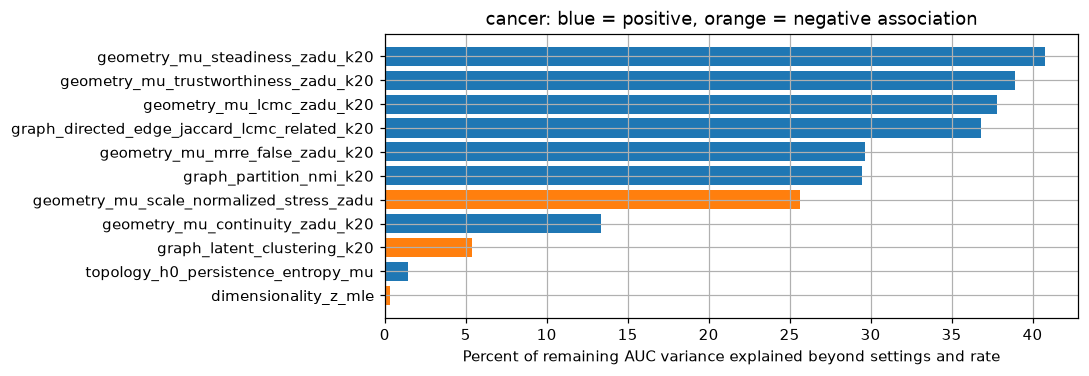

sex_mixed — AUC beyond beta, dimension, seed and rate


,metric,pearson,spearman,coefficient,partial_r2,delta_r2,q_cluster,n
45,topology_h1_normalized_wasserstein,0.930980,0.952381,0.081392,0.146248,0.012387,0.011838,186
34,graph_directed_edge_jaccard_lcmc_related_k20,0.864722,0.964286,0.082824,0.128332,0.010869,0.062135,186
28,geometry_mu_lcmc_zadu_k20,0.844840,0.964286,0.075585,0.109165,0.009246,0.062135,186
38,graph_latent_clustering_k20,-0.821297,-0.964286,-0.072599,0.095049,0.008050,0.062135,186
26,geometry_mu_cohesiveness_zadu_k20,0.911582,0.880952,0.022054,0.036740,0.003112,0.062135,186
36,graph_hub_identity_spearman_k20,0.845849,0.821429,0.028142,0.036149,0.003062,0.086650,186
42,info_total_correlation_autoencodix,0.851421,0.880952,-0.044488,0.024981,0.002116,0.352235,186
30,geometry_mu_mrre_false_zadu_k20,0.768376,0.928571,0.029813,0.024972,0.002115,0.062135,186
32,geometry_mu_trustworthiness_zadu_k20,0.751964,0.928571,0.037704,0.024138,0.002044,0.078727,186
40,graph_latent_lambda2_k20,0.889939,0.845238,0.012299,0.014863,0.001259,0.352235,186


Rate baseline after beta, dimension and seed:


,partial_r2,coefficient,q_cluster,n
169,0.010201,0.042035,0.415363,186


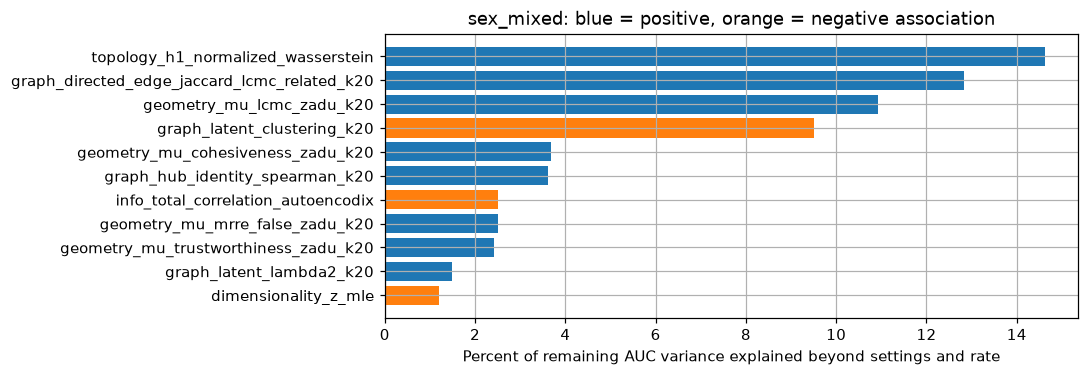

In [6]:
focus_results = focus.merge(results, on=['task', 'metric'], how='left', validate='one_to_many')
for task in TASKS:
    subset = focus_results[focus_results.task.eq(task)
        & focus_results.adjustment.eq('settings_and_rate') & focus_results.status.eq('ok')]
    subset = subset.sort_values('partial_r2', ascending=False)
    print(task, '— AUC beyond beta, dimension, seed and rate')
    display(subset[['metric', 'pearson', 'spearman', 'coefficient', 'partial_r2',
                    'delta_r2', 'q_cluster', 'n']])
    baseline = results[results.task.eq(task) & results.metric.eq('log_rate')]
    print('Rate baseline after beta, dimension and seed:')
    display(baseline[['partial_r2', 'coefficient', 'q_cluster', 'n']])
    fig, ax = plt.subplots(figsize=(10, max(3, .32 * len(subset))))
    plot = subset.iloc[::-1]
    ax.barh(plot.metric, 100 * plot.partial_r2,
            color=np.where(plot.coefficient.ge(0), 'tab:blue', 'tab:orange'))
    ax.set_xlabel('Percent of remaining AUC variance explained beyond settings and rate')
    ax.set_title(f'{task}: blue = positive, orange = negative association')
    fig.tight_layout()
    fig.savefig(OUTPUT / f'{task}_focus_auc_beyond_rate.png', dpi=160)
    plt.show()
focus_results.to_csv(OUTPUT / 'focus_auc_ancova.csv', index=False)


## Varianzzerlegung der Metriken

Sequenzielle R²-Zerlegung: **Dimension → β → β×Dimension → Seed → Rest**. Die Anteile summieren sich zu 1, hängen aber von dieser festgelegten Reihenfolge ab; sie sind keine eindeutig identifizierten kausalen Varianzkomponenten.

Ein großer β-Anteil allein macht ein Maß noch nicht nutzlos. Ein gemeinsamer Seed-Effekt allein belegt ebenfalls keinen AUC-Nutzen. Entscheidend bleibt der zusätzliche Zusammenhang mit AUC nach Kontrolle der Einstellungen und Rate.


,n,dimension_share,beta_share,beta_dimension_interaction_share,seed_share,residual_share
metric,,,,,,
geometry_mu_cohesiveness_zadu_k20,210,0.355001,0.484454,0.033735,0.007011,0.119799
graph_latent_lambda2_k20,210,0.262766,0.505092,0.116230,0.006104,0.109807
graph_hub_identity_spearman_k20,210,0.279637,0.601071,0.049614,0.001050,0.068627
graph_partition_nmi_k20,210,0.117235,0.808789,0.021397,0.001650,0.050930
geometry_mu_mrre_false_zadu_k20,210,0.088892,0.860159,0.005631,0.001231,0.044087
geometry_mu_steadiness_zadu_k20,210,0.092984,0.846667,0.019104,0.002073,0.039171
topology_h1_normalized_wasserstein,210,0.342876,0.531813,0.086914,0.002384,0.036012
topology_h0_persistence_entropy_mu,210,0.077993,0.863708,0.022534,0.002763,0.033002
geometry_mu_lcmc_zadu_k20,210,0.186275,0.762710,0.020663,0.000838,0.029513


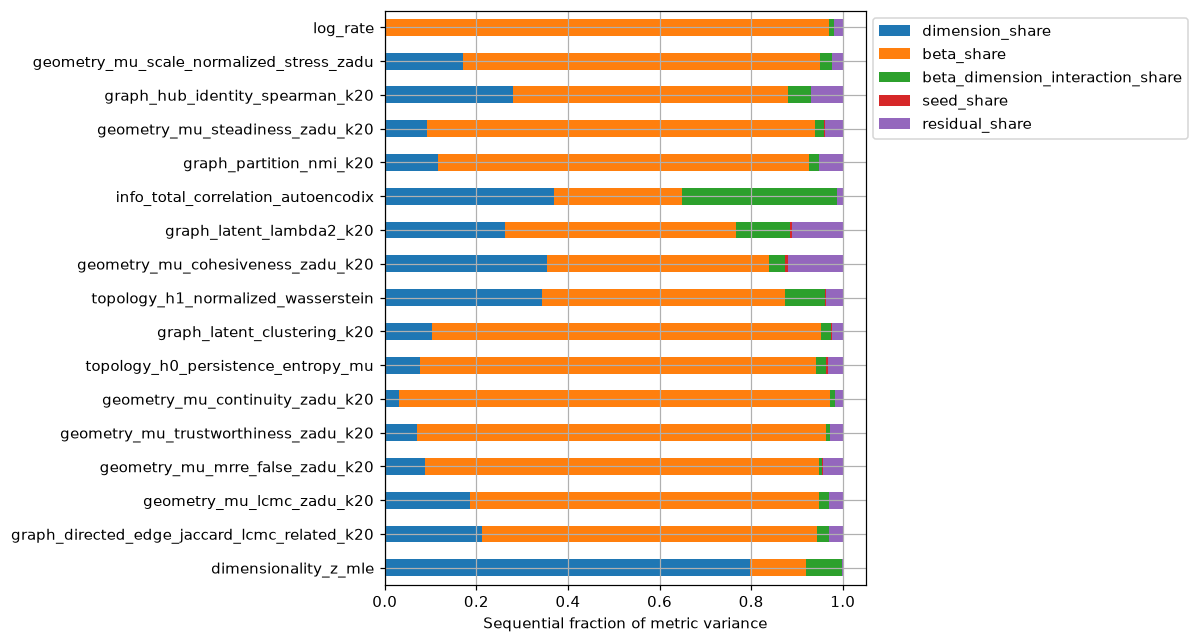

In [7]:
variance_rows = []
for metric in METRICS:
    sample = data.replace([np.inf, -np.inf], np.nan).dropna(subset=[metric]).copy()
    if EXCLUDE_FULL_COLLAPSE:
        sample = sample[sample.posterior_collapsed_dimensions_fraction_eps_0p01_delta_0p01.lt(1)]
    if len(sample) < 10 or sample[metric].std() < 1e-12:
        continue
    sample['metric_value'] = sample[metric]
    formulas = ['metric_value ~ C(latent_dim)',
                'metric_value ~ C(latent_dim) + C(beta_level)',
                'metric_value ~ C(settings_cell)',
                'metric_value ~ C(settings_cell) + C(seed)']
    r2 = [smf.ols(formula, sample).fit().rsquared for formula in formulas]
    variance_rows.append(dict(metric=metric, n=len(sample), dimension_share=r2[0],
        beta_share=r2[1]-r2[0], beta_dimension_interaction_share=r2[2]-r2[1],
        seed_share=r2[3]-r2[2], residual_share=1-r2[3]))
variance = pd.DataFrame(variance_rows)
variance.to_csv(OUTPUT / 'metric_variance_decomposition.csv', index=False)
selected = variance[variance.metric.isin(focus.metric)].set_index('metric')
shares = ['dimension_share', 'beta_share', 'beta_dimension_interaction_share', 'seed_share', 'residual_share']
assert np.allclose(variance[shares].sum(axis=1), 1)
display(selected.sort_values('residual_share', ascending=False))
ax = selected[shares].plot.barh(stacked=True, figsize=(11, max(4, .35 * len(selected))))
ax.set(xlabel='Sequential fraction of metric variance', ylabel='')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
ax.figure.tight_layout()
ax.figure.savefig(OUTPUT / 'focus_metric_variance_decomposition.png', dpi=160)
plt.show()


## Resampling: Sensitivität der zusätzlichen AUC-Assoziation

**Residual-Permutation (Freedman–Lane-artig):** Das reduzierte AUC-Modell enthält β/d×Dimension, Seed und log-Rate. Seine Residuen werden nur **innerhalb gleicher β/d- und Dimensions-Zellen** permutiert, danach wird auf dieselben Kovariaten projiziert und partielles R² berechnet. Das erhält das Nullmodell besser als ein direktes Shuffle der Metrik. Trotzdem setzt es Austauschbarkeit der Residuen voraus und kann Abhängigkeiten über β innerhalb eines Seeds zerstören: **kein exakter, universell heteroskedastizitätsrobuster Test**.

Zusätzlich: **Wild-Cluster-Sensitivität**, ein gemeinsames zufälliges Vorzeichen je (Dimension, Seed)-Trajektorie. Das erhält deren Abhängigkeitsmuster, benötigt aber ebenfalls Annahmen; mit 24 Clustern bleibt Unsicherheit. 1000 Ziehungen, Seed 31; kleinster p-Wert 1/1001. BH je Aufgabe innerhalb der explorativen Kandidatenmenge. Die Cluster-q-Werte oben wurden dagegen über das gesamte Screening korrigiert.

AUC liegt in [0,1], nicht [0.5,1]. Die Primäranalyse bleibt auf der Originalskala; ein Logit wäre eine gesondert auszuweisende Sensitivitätsanalyse.


In [8]:
def resample_auc_association(task, metric):
    sample = data.replace([np.inf, -np.inf], np.nan).dropna(subset=[TASKS[task], metric, 'log_rate']).copy()
    if EXCLUDE_FULL_COLLAPSE:
        sample = sample[sample.posterior_collapsed_dimensions_fraction_eps_0p01_delta_0p01.lt(1)]
    sample = sample.reset_index(drop=True)
    sample['auc'] = sample[TASKS[task]]
    base = smf.ols('auc ~ C(settings_cell) + C(seed) + log_rate', sample).fit()
    # An SVD basis handles any rank-deficient nuisance columns explicitly.
    u, singular, _ = np.linalg.svd(base.model.exog, full_matrices=False)
    basis = u[:, singular > singular.max() * 1e-12]
    metric_values = sample[metric].to_numpy()
    metric_residual = metric_values - basis @ (basis.T @ metric_values)
    metric_norm = metric_residual @ metric_residual
    if metric_norm < 1e-20 or base.ssr < 1e-20:
        return dict(task=task, metric=metric, status='not_identifiable')
    residual = base.resid.to_numpy()
    observed = (metric_residual @ residual)**2 / (metric_norm * (residual @ residual))
    rng = np.random.default_rng(RESAMPLING_SEED)
    permuted = np.tile(residual[:, None], (1, N_RESAMPLES))
    for indices in sample.groupby('settings_cell').indices.values():
        for draw in range(N_RESAMPLES):
            permuted[indices, draw] = rng.permutation(residual[indices])
    cluster_codes, clusters = pd.factorize(sample.trajectory)
    signs = rng.choice([-1., 1.], size=(len(clusters), N_RESAMPLES))
    wild = residual[:, None] * signs[cluster_codes]
    p_values = {}
    for name, draws in [('permutation', permuted), ('wild_cluster', wild)]:
        draws = draws - basis @ (basis.T @ draws)
        denominator = metric_norm * np.sum(draws**2, axis=0)
        statistic = np.divide((metric_residual @ draws)**2, denominator,
                              out=np.zeros(N_RESAMPLES), where=denominator > 0)
        p_values['p_' + name] = (1 + np.sum(statistic >= observed)) / (N_RESAMPLES + 1)
    return dict(task=task, metric=metric, status='ok', n=len(sample),
                partial_r2_resampling=observed, **p_values)

resampling = pd.DataFrame([resample_auc_association(row.task, row.metric)
    for row in focus.itertuples(index=False) if row.metric != 'log_rate'])
for task, group in resampling[resampling.status.eq('ok')].groupby('task'):
    for name in ['permutation', 'wild_cluster']:
        resampling.loc[group.index, 'q_' + name] = multipletests(group['p_' + name], method='fdr_bh')[1]
resampling.to_csv(OUTPUT / 'focus_auc_resampling.csv', index=False)
for task in TASKS:
    joined = focus_results[focus_results.task.eq(task) & focus_results.adjustment.eq('settings_and_rate')]
    joined = joined.merge(resampling, on=['task', 'metric'], suffixes=('', '_resampling'), validate='one_to_one')
    assert np.allclose(joined.partial_r2, joined.partial_r2_resampling, atol=1e-8, equal_nan=True)
    print(task, '— effect size and resampling sensitivity (exploratory)')
    display(joined.sort_values('partial_r2', ascending=False)[['metric', 'pearson', 'spearman',
        'partial_r2', 'q_cluster', 'p_permutation', 'q_permutation', 'p_wild_cluster', 'q_wild_cluster']])


cancer — effect size and resampling sensitivity (exploratory)


,metric,pearson,spearman,partial_r2,q_cluster,p_permutation,q_permutation,p_wild_cluster,q_wild_cluster
5,geometry_mu_steadiness_zadu_k20,0.982308,0.857143,0.407695,6.075089e-10,0.000999,0.001570,0.011988,0.018838
6,geometry_mu_trustworthiness_zadu_k20,0.988134,0.976190,0.388883,5.917396e-05,0.000999,0.001570,0.003996,0.007326
2,geometry_mu_lcmc_zadu_k20,0.984278,0.976190,0.377781,2.850769e-05,0.000999,0.001570,0.000999,0.005495
7,graph_directed_edge_jaccard_lcmc_related_k20,0.978814,0.976190,0.368411,7.152846e-05,0.000999,0.001570,0.000999,0.005495
3,geometry_mu_mrre_false_zadu_k20,0.990318,0.976190,0.296598,5.290807e-03,0.000999,0.001570,0.003996,0.007326
9,graph_partition_nmi_k20,0.980063,0.869048,0.294695,4.755711e-04,0.000999,0.001570,0.002997,0.007326
4,geometry_mu_scale_normalized_stress_zadu,-0.981008,-0.815476,0.256147,1.034944e-03,0.000999,0.001570,0.003996,0.007326
1,geometry_mu_continuity_zadu_k20,0.974437,0.964286,0.133829,1.563156e-01,0.022977,0.031593,0.084915,0.116758
8,graph_latent_clustering_k20,-0.979170,-0.964286,0.054166,1.640719e-01,0.098901,0.120879,0.173826,0.212454
10,topology_h0_persistence_entropy_mu,0.989940,0.964286,0.014351,5.396397e-01,0.476523,0.476523,0.450549,0.450549


sex_mixed — effect size and resampling sensitivity (exploratory)


,metric,pearson,spearman,partial_r2,q_cluster,p_permutation,q_permutation,p_wild_cluster,q_wild_cluster
10,topology_h1_normalized_wasserstein,0.930980,0.952381,0.146248,0.011838,0.000999,0.002747,0.000999,0.008242
5,graph_directed_edge_jaccard_lcmc_related_k20,0.864722,0.964286,0.128332,0.062135,0.000999,0.002747,0.002997,0.008242
2,geometry_mu_lcmc_zadu_k20,0.844840,0.964286,0.109165,0.062135,0.000999,0.002747,0.002997,0.008242
7,graph_latent_clustering_k20,-0.821297,-0.964286,0.095049,0.062135,0.000999,0.002747,0.002997,0.008242
1,geometry_mu_cohesiveness_zadu_k20,0.911582,0.880952,0.036740,0.062135,0.013986,0.021978,0.021978,0.048352
6,graph_hub_identity_spearman_k20,0.845849,0.821429,0.036149,0.086650,0.020979,0.028846,0.028971,0.053114
9,info_total_correlation_autoencodix,0.851421,0.880952,0.024981,0.352235,0.084915,0.103785,0.229770,0.229770
3,geometry_mu_mrre_false_zadu_k20,0.768376,0.928571,0.024972,0.062135,0.005994,0.013187,0.033966,0.053375
4,geometry_mu_trustworthiness_zadu_k20,0.751964,0.928571,0.024138,0.078727,0.012987,0.021978,0.043956,0.060440
8,graph_latent_lambda2_k20,0.889939,0.845238,0.014863,0.352235,0.158841,0.174725,0.200799,0.220879


## Anhang: vollständige Ranglisten
Alle Tests bleiben in `metric_anova.csv`. Für sämtliche Tabellen/Plots `SHOW_FULL_SCREENING=True` setzen.


In [9]:
if SHOW_FULL_SCREENING:
    columns = ['metric', 'family', 'n', 'coverage', 'coefficient', 'partial_r2', 'delta_r2',
               'p_F', 'q_F', 'p_cluster', 'q_cluster']
    for task in TASKS:
        for adjustment in ('settings', 'settings_and_rate'):
            subset = results[results.task.eq(task) & results.adjustment.eq(adjustment) & results.status.eq('ok')]
            print(f'{task}: {adjustment}; {int(subset.q_cluster.lt(ALPHA).sum())} / {len(subset)} with q_cluster < {ALPHA}')
            display(subset[columns].head(15))
            plot = subset.sort_values('partial_r2', ascending=False).head(12).iloc[::-1]
            fig, ax = plt.subplots(figsize=(10, 5))
            ax.barh(plot.metric, plot.partial_r2,
                    color=np.where(plot.q_cluster.lt(ALPHA), 'tab:blue', 'lightgray'))
            ax.set_xlabel('Partial R²: fraction of remaining AUC variance explained')
            ax.set_title(f'{task} — {adjustment}; blue: BH q_cluster < {ALPHA}')
            fig.tight_layout()
            fig.savefig(OUTPUT / f'{task}_{adjustment}_partial_r2.png', dpi=160)
            plt.show()


## 4. Residualplots und Diagnostik

Die Residualplots entfernen die Einstellungs-Zellmittelwerte und den additiven Seed-Effekt aus AUC und Metrik. Sie zeigen die verbleibende Assoziation. QQ- und Residualplots prüfen grobe Abweichungen der linearen Modellannahmen; sie ersetzen keine unabhängige Validierung.


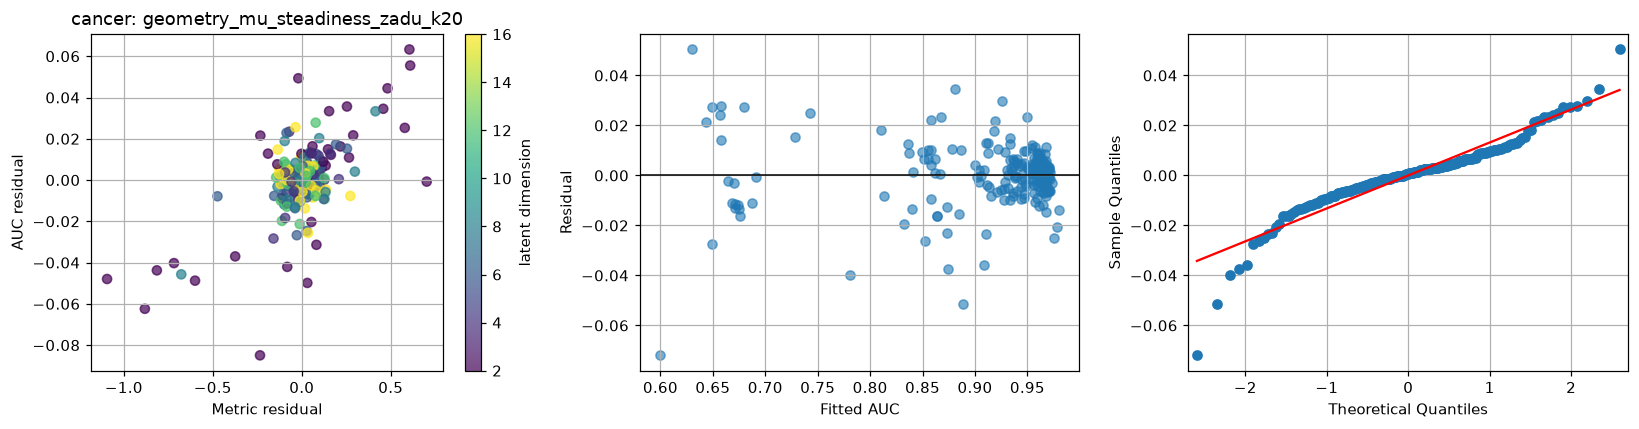

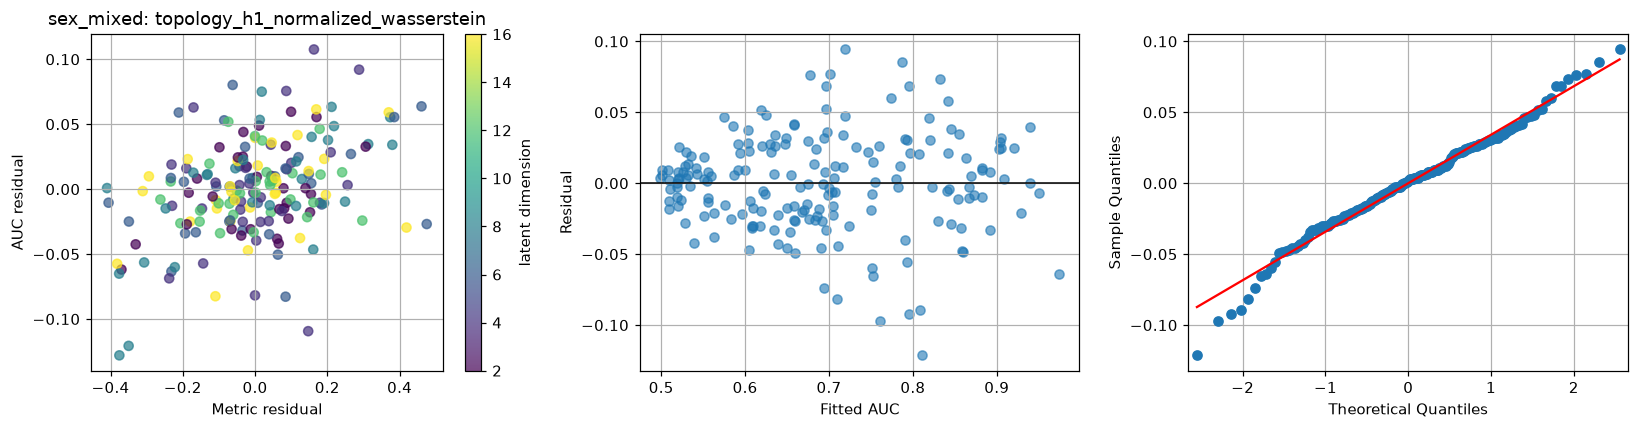

In [10]:
for task, target in TASKS.items():
    candidates = results[results.task.eq(task) & results.adjustment.eq('settings_and_rate') & results.status.eq('ok')]
    metric = candidates.iloc[0].metric
    sample = data.replace([np.inf, -np.inf], np.nan).dropna(subset=[target, metric, 'log_rate']).copy()
    if EXCLUDE_FULL_COLLAPSE:
        sample = sample[sample.posterior_collapsed_dimensions_fraction_eps_0p01_delta_0p01.lt(1)]
    sample['auc'] = sample[target]
    sample['metric_z'] = (sample[metric] - sample[metric].mean()) / sample[metric].std()
    base = smf.ols('auc ~ C(settings_cell) + C(seed) + log_rate', sample).fit()
    residual_metric = sm.OLS(sample.metric_z, base.model.exog).fit().resid
    fitted = smf.ols('auc ~ C(settings_cell) + C(seed) + log_rate + metric_z', sample).fit()
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    points = axes[0].scatter(residual_metric, base.resid, c=sample.latent_dim, alpha=.7)
    fig.colorbar(points, ax=axes[0], label='latent dimension')
    axes[0].set(xlabel='Metric residual', ylabel='AUC residual', title=f'{task}: {metric}')
    axes[1].scatter(fitted.fittedvalues, fitted.resid, alpha=.6)
    axes[1].axhline(0, color='black', lw=1)
    axes[1].set(xlabel='Fitted AUC', ylabel='Residual')
    sm.qqplot(fitted.resid, line='s', ax=axes[2])
    fig.tight_layout()
    fig.savefig(OUTPUT / f'{task}_diagnostics.png', dpi=160)
    plt.show()


## Grenzen und gespeicherte Ergebnisse

- Cancer und Sex haben unterschiedliche Kohorten und Auswertungssplits; ihre p-Werte sind nicht direkt vergleichbar.
- Die 56 Metriken wurden bereits auf diesen Daten untersucht: FDR macht daraus keine unabhängige Bestätigung.
- β-Zustände derselben Seed-/Dimensions-Trajektorie können abhängig sein. Cluster-p-Werte beruhen hier auf nur 24 Clustern.
- Kleine Unterschiede bei festem β können mit vier Seeds sehr unsicher sein. Keine automatische Metrikauswahl für Large Scale aus einem einzelnen p-Wert.
- `settings_and_rate` beschreibt eine bedingte Assoziation; die Rate ist selbst ein Trainingsergebnis, keine randomisierte Kontrollvariable.
- Nach Bestätigung auf neuen Seeds/Kohorten fragen; die neue 750-Epochen-Serie ist hier ausdrücklich nicht eingemischt.


In [11]:
provenance = dict(
    source=str(source_path), sex_source=str(sex_path), metric_selection=str(selection_path),
    sha256={str(path): hashlib.sha256(path.read_bytes()).hexdigest()
            for path in (source_path, sex_path, selection_path)},
    runs=len(data), epochs=90, metrics=METRICS, min_coverage=MIN_COVERAGE,
    correlation_source=str(correlation_path),
    correlation_source_sha256=hashlib.sha256(correlation_path.read_bytes()).hexdigest(),
    shortlist='Union of top 8 absolute Pearson and top 8 absolute Spearman per task',
    resamples=N_RESAMPLES, resampling_seed=RESAMPLING_SEED,
    resampling_methods=['reduced-model residual permutation within beta/d x dimension cells',
                        'Rademacher signs per dimension x seed trajectory'],
    exclude_full_collapse=EXCLUDE_FULL_COLLAPSE,
    baseline='AUC ~ C(beta/d x latent_dimension cell) + C(seed)',
    cluster='latent_dimension x seed',
    multiple_testing='BH separately by task and adjustment; exploratory',
    cancer_protocol='native validation z AUC', sex_protocol='historical mixed cancers, pooled validation+test, one z draw',
)
(OUTPUT / 'provenance.json').write_text(json.dumps(provenance, indent=2) + '\n')
print('Saved tables, figures and provenance:', OUTPUT)


Saved tables, figures and provenance: /home/nickok/Projects/MasterThesis/vae-beta-control/beta_vae_experiments/analysis_results/anova_26_09
